# Домашнее задание 1. Введение в Pytorch и DL. Базовые элементы.

# Задание 1

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

torch.manual_seed(42)

Using cpu device


In [ ]:
def init_constant_zero(layer):     # Все веса = 0
    nn.init.constant_(layer.weight, 0)
    nn.init.constant_(layer.bias, 0)


def init_constant_small(layer):    # Все веса = 0.01
    nn.init.constant_(layer.weight, 0.01)
    nn.init.constant_(layer.bias, 0)


def init_small_normal(layer):     # Маленькие случайные веса. Нормальное распределение
    nn.init.normal_(layer.weight, mean=0.0, std=0.01)
    nn.init.constant_(layer.bias, 0)


def init_xavier(layer):     # Ксавье
    nn.init.xavier_normal_(layer.weight)
    nn.init.constant_(layer.bias, 0)


def init_kaiming(layer):     # Каймин Хэ
    nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
    nn.init.constant_(layer.bias, 0)

INIT_FUNCS = {
    "constant_zero": init_constant_zero,
    "constant_small": init_constant_small,
    "small_normal": init_small_normal,
    "xavier": init_xavier,
    "kaiming": init_kaiming,
}

In [3]:
class BaseNetwork(nn.Module):
    
    def __init__(self, act_fn, input_size=784, num_classes=10, hidden_sizes=[512, 256, 256, 128]):
        """
        Inputs:
            act_fn - Object of the activation function that should be used as non-linearity in the network.
            input_size - Size of the input images in pixels
            num_classes - Number of classes we want to predict
            hidden_sizes - A list of integers specifying the hidden layer sizes in the NN
        """
        super().__init__()
        
        # Create the network based on the specified hidden sizes
        layers = []
        layer_sizes = [input_size] + hidden_sizes
        for layer_index in range(1, len(layer_sizes)):
            layers += [nn.Linear(layer_sizes[layer_index-1], layer_sizes[layer_index]),
                       act_fn]
        layers += [nn.Linear(layer_sizes[-1], num_classes)]
        self.layers = nn.ModuleList(layers) # A module list registers a list of modules as submodules (e.g. for parameters)
        
        self.config = {"act_fn": act_fn.__class__.__name__, "input_size": input_size, "num_classes": num_classes, "hidden_sizes": hidden_sizes} 
        
    def forward(self, x):
        x = x.view(x.size(0), -1)
        for l in self.layers:
            x = l(x)
        return x

In [4]:
def use_init(model, init_name):
    init_fn = INIT_FUNCS[init_name]
    for module in model.modules():
        if isinstance(module, nn.Linear):
            init_fn(module)

# Снимаем активации
def get_activations(model, x):
    activations = []
    hooks = []

    def hook_fn(module, input, output):
        activations.append(output.detach().flatten().cpu())

    for module in model.modules():
        if isinstance(module, nn.Linear):
            hooks.append(module.register_forward_hook(hook_fn))

    with torch.no_grad():
        model(x)

    for h in hooks:
        h.remove()

    return activations

def activation_stats(model, x):
    activations = get_activations(model, x)
    stats = []
    for a in activations:
        stats.append({
            "mean": a.mean().item(),
            "std": a.std().item(),
            "min": a.min().item(),
            "max": a.max().item(),
        })
    return stats

# Снимаем градиенты
def get_gradients(model, x, y, loss_fn):
    model.zero_grad()
    out = model(x)
    loss = loss_fn(out, y)
    loss.backward()

    grads = []
    for module in model.modules():
        if isinstance(module, nn.Linear):
            grads.append(module.weight.grad.detach().flatten().cpu().clone())

    return grads, loss.item()

def gradient_stats(model, x, y, loss_fn):
    grads, loss = get_gradients(model, x, y, loss_fn)
    stats = []
    for g in grads:
        stats.append({
            "mean": g.mean().item(),
            "std": g.std().item(),
            "abs_mean": g.abs().mean().item(),
        })
    return stats, loss


In [5]:
ACTIVATIONS = {
    "ReLU": nn.ReLU(),
    "Tanh": nn.Tanh(),
    "Identity": nn.Identity(),
}

INITS = ["constant_zero", "constant_small", "small_normal", "xavier", "kaiming"]

results = {}

for act_name, act_fn in ACTIVATIONS.items():
    for init_name in INITS:
        model = BaseNetwork(act_fn=act_fn)
        use_init(model, init_name)

        x = torch.randn(64, 1, 28, 28)
        y = torch.randint(0, 10, (64,))
        loss_fn = nn.CrossEntropyLoss()

        acts = activation_stats(model, x)
        grads, loss = gradient_stats(model, x, y, loss_fn)

        results[(act_name, init_name)] = {
            "acts": acts,
            "grads": grads,
            "loss": loss,
        }
        print(f"{act_name} + {init_name}: loss={loss:.4f}, "
              f"act_std_layer0={acts[0]['std']:.4f}, "
              f"act_std_layer4={acts[-1]['std']:.4f}, "
              f"grad_std_layer0={grads[0]['std']:.6f}, " 
              f"grad_std_layer4={grads[-1]['std']:.6f}")

ReLU + constant_zero: loss=2.3026, act_std_layer0=0.0000, act_std_layer4=0.0000, grad_std_layer0=0.000000, grad_std_layer4=0.000000
ReLU + constant_small: loss=2.3026, act_std_layer0=0.3096, act_std_layer4=8.8695, grad_std_layer0=0.000000, grad_std_layer4=0.399516
ReLU + small_normal: loss=2.3026, act_std_layer0=0.2791, act_std_layer4=0.0000, grad_std_layer0=0.000001, grad_std_layer4=0.000011
ReLU + xavier: loss=2.3737, act_std_layer0=1.0943, act_std_layer4=0.5142, grad_std_layer0=0.002473, grad_std_layer4=0.018583
ReLU + kaiming: loss=4.4320, act_std_layer0=1.4180, act_std_layer4=2.5192, grad_std_layer0=0.007045, grad_std_layer4=0.147489
Tanh + constant_zero: loss=2.3026, act_std_layer0=0.0000, act_std_layer4=0.0000, grad_std_layer0=0.000000, grad_std_layer4=0.000000
Tanh + constant_small: loss=2.3026, act_std_layer0=0.2512, act_std_layer4=1.2120, grad_std_layer0=0.000000, grad_std_layer4=0.033193
Tanh + small_normal: loss=2.3025, act_std_layer0=0.2802, act_std_layer4=0.0002, grad_std

In [6]:
def plot_histograms(act_name, init_name, acts, grads):
    n_layers = len(acts)
    fig, axes = plt.subplots(2, n_layers, figsize=(4 * n_layers, 8))

    for i in range(n_layers):
        axes[0, i].hist(acts[i].numpy(), bins=50, alpha=0.7)
        axes[0, i].set_title(f"Act Layer {i}")
        axes[0, i].set_xlabel("value")

        axes[1, i].hist(grads[i].numpy(), bins=50, alpha=0.7, color='orange')
        axes[1, i].set_title(f"Grad Layer {i}")
        axes[1, i].set_xlabel("value")

    fig.suptitle(f"{act_name} + {init_name}", fontsize=14)
    plt.tight_layout()
    plt.show()


=== ReLU + kaiming ===
Loss: 3.1776
Act std по слоям: ['1.4132', '1.4111', '1.3499', '1.4472', '1.5090']
Grad std по слоям: ['0.002659', '0.006872', '0.010527', '0.017489', '0.076379']


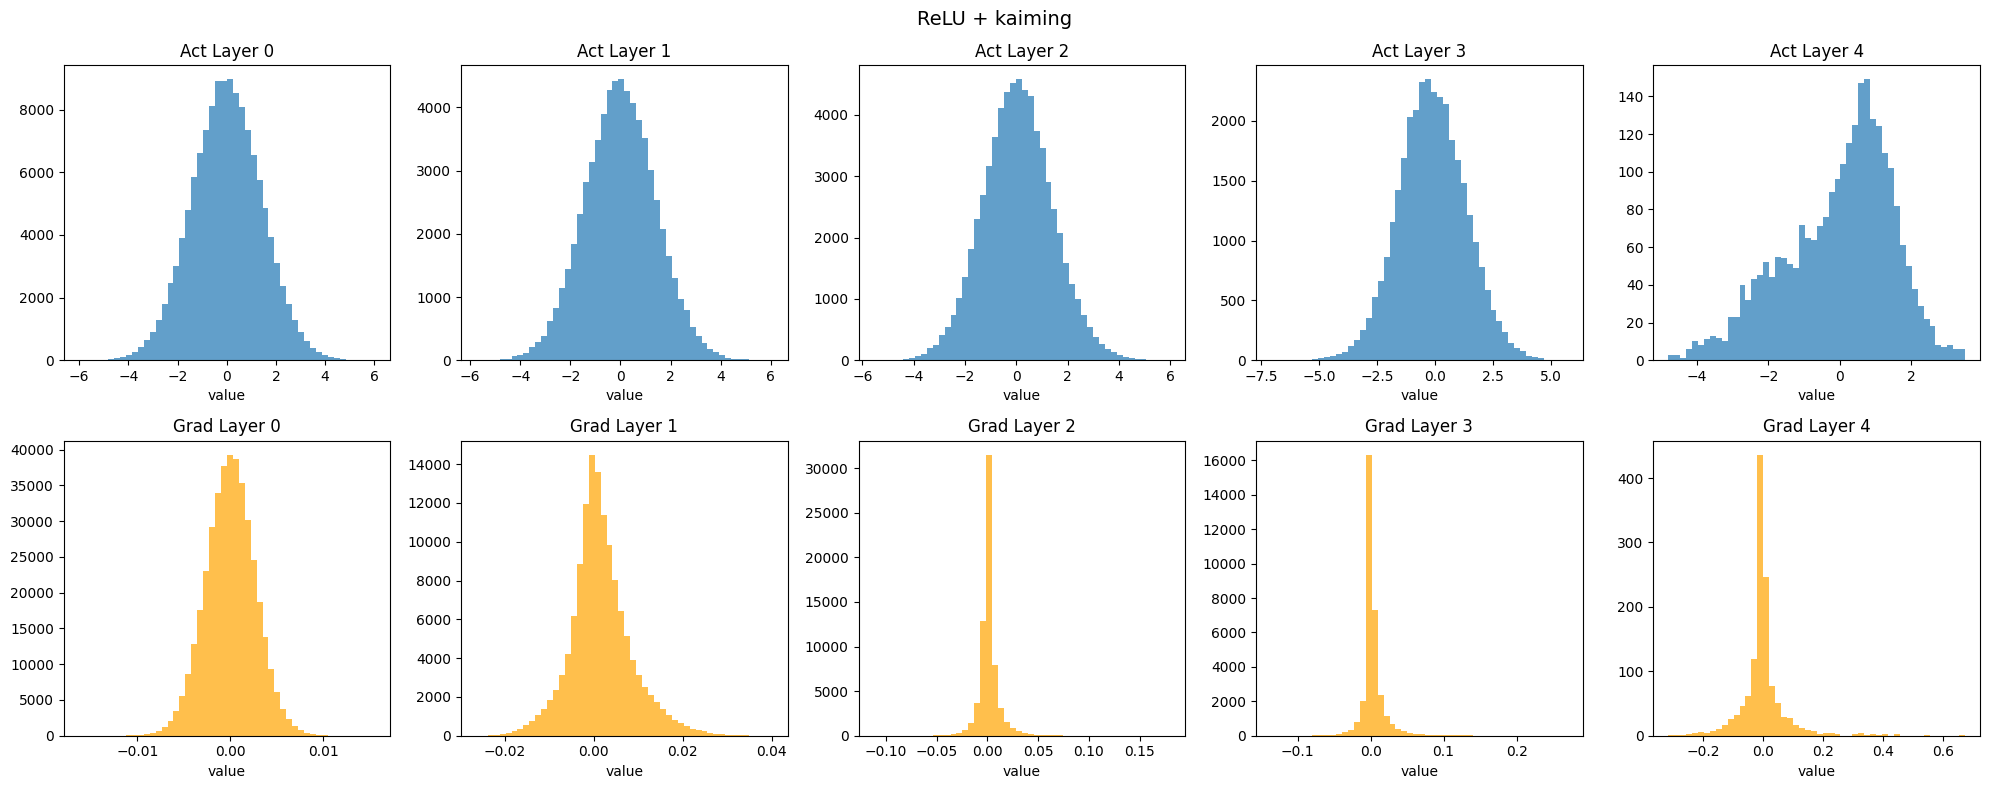


=== ReLU + small_normal ===
Loss: 2.3026
Act std по слоям: ['0.2796', '0.0454', '0.0050', '0.0005', '0.0000']
Grad std по слоям: ['0.000000', '0.000001', '0.000001', '0.000002', '0.000008']


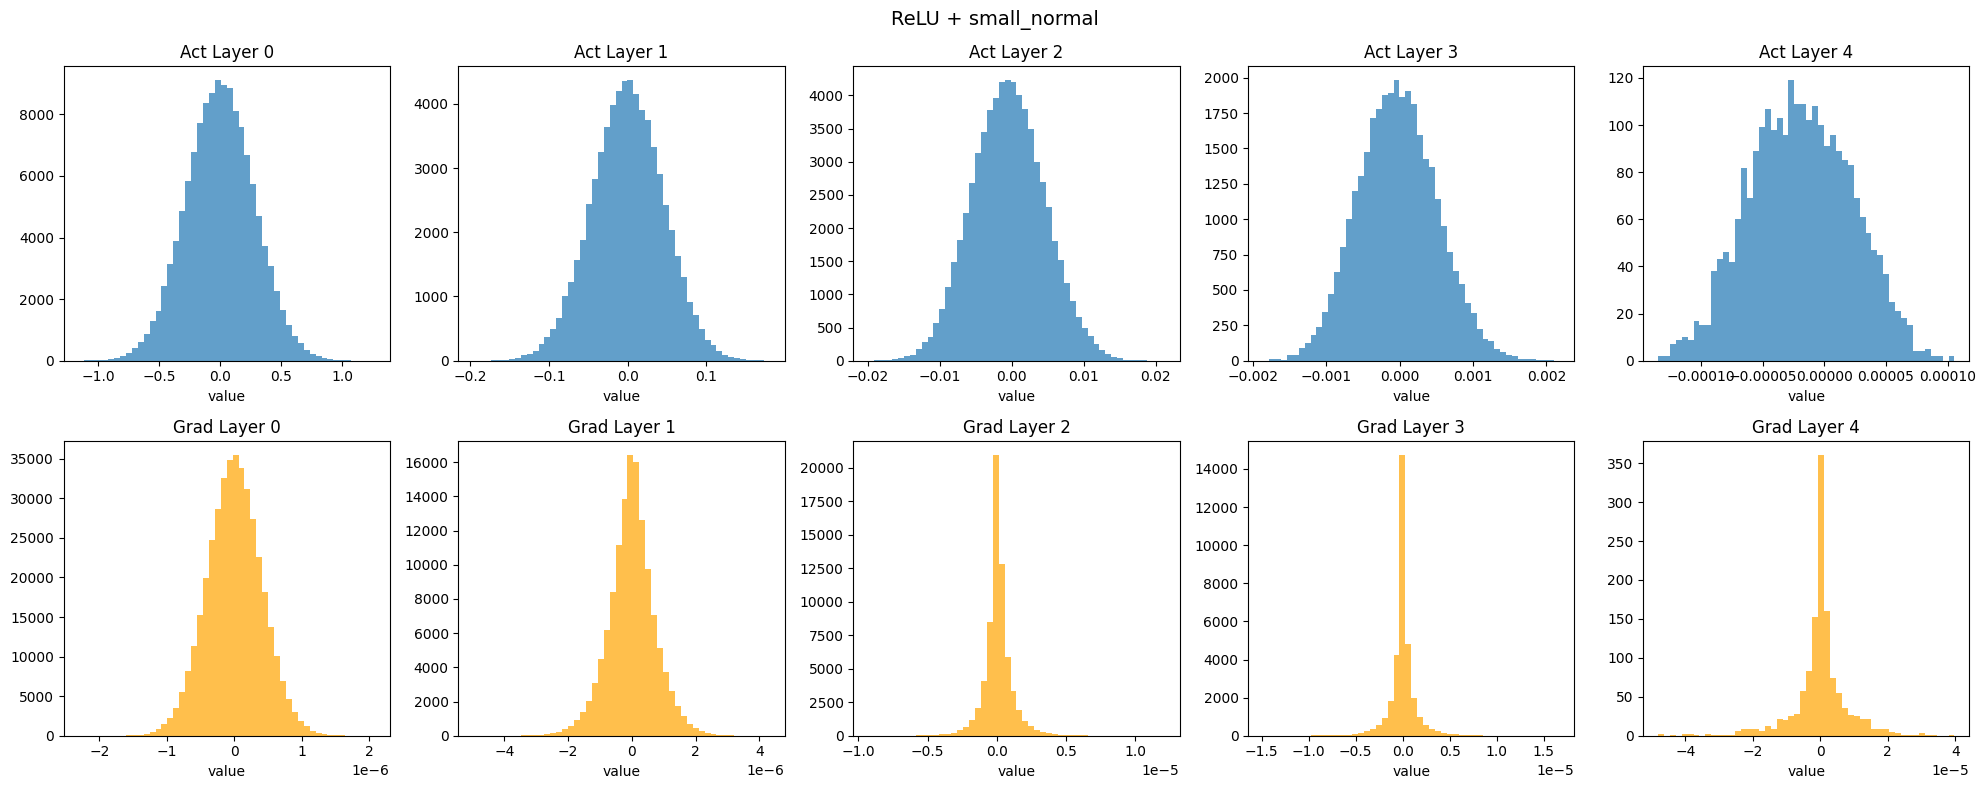


=== Tanh + xavier ===
Loss: 2.5497
Act std по слоям: ['1.0998', '0.7574', '0.5384', '0.5046', '0.5930']
Grad std по слоям: ['0.001697', '0.002072', '0.002352', '0.002938', '0.008863']


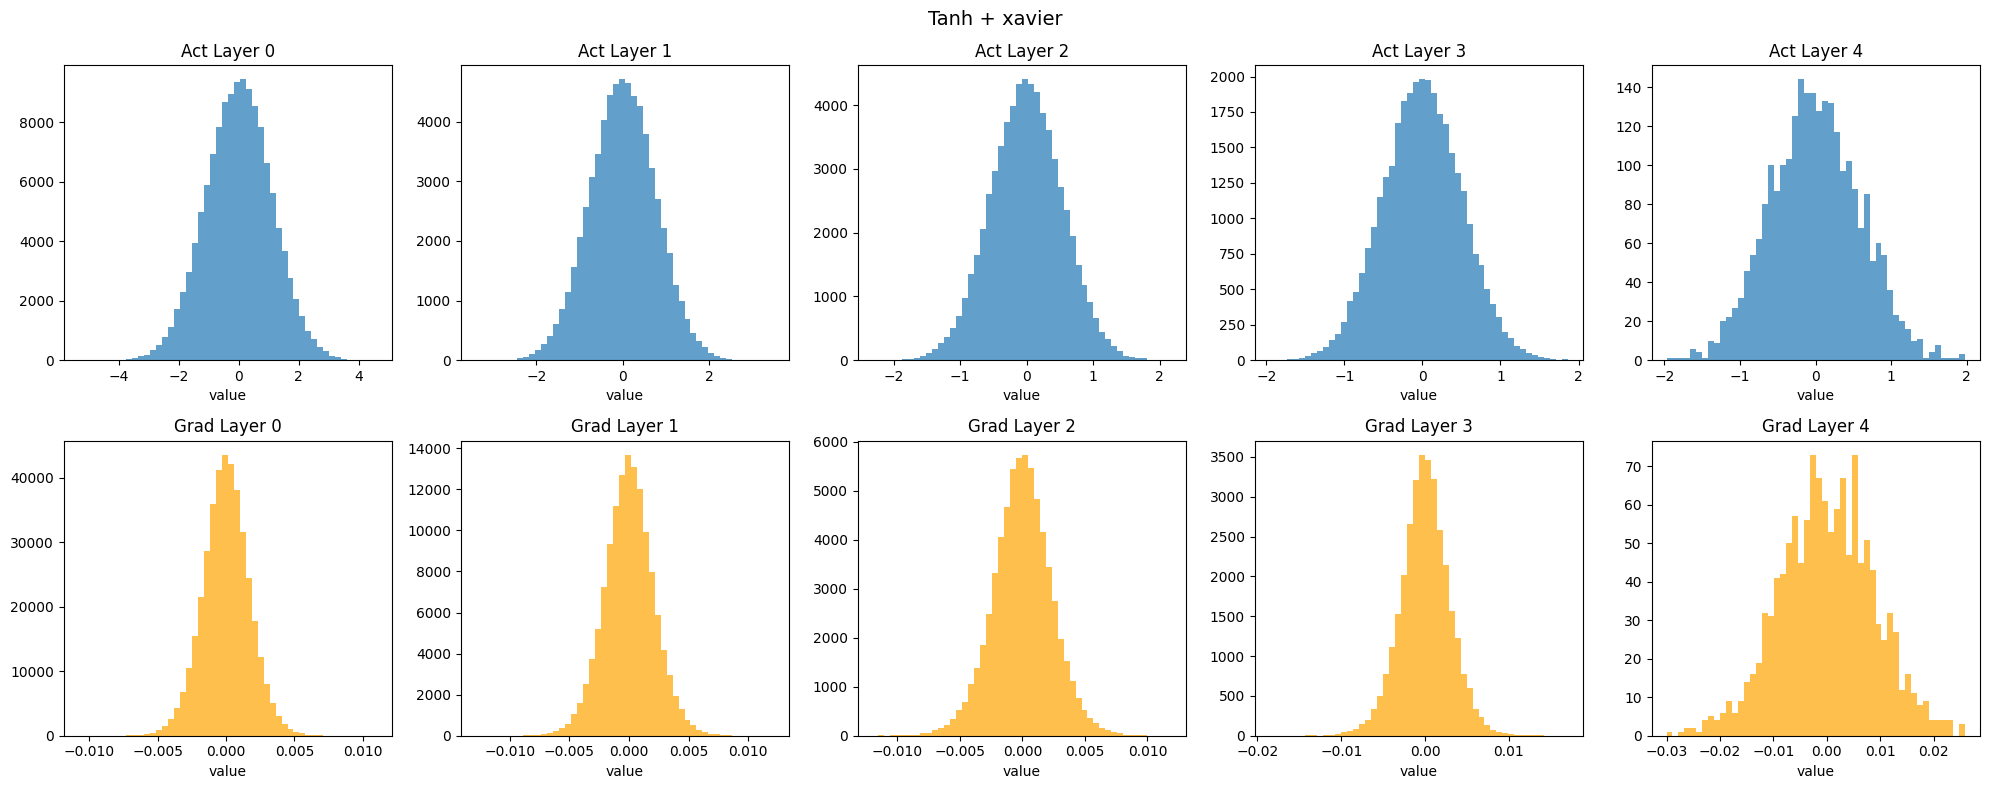


=== ReLU + constant_zero ===
Loss: 2.3026
Act std по слоям: ['0.0000', '0.0000', '0.0000', '0.0000', '0.0000']
Grad std по слоям: ['0.000000', '0.000000', '0.000000', '0.000000', '0.000000']


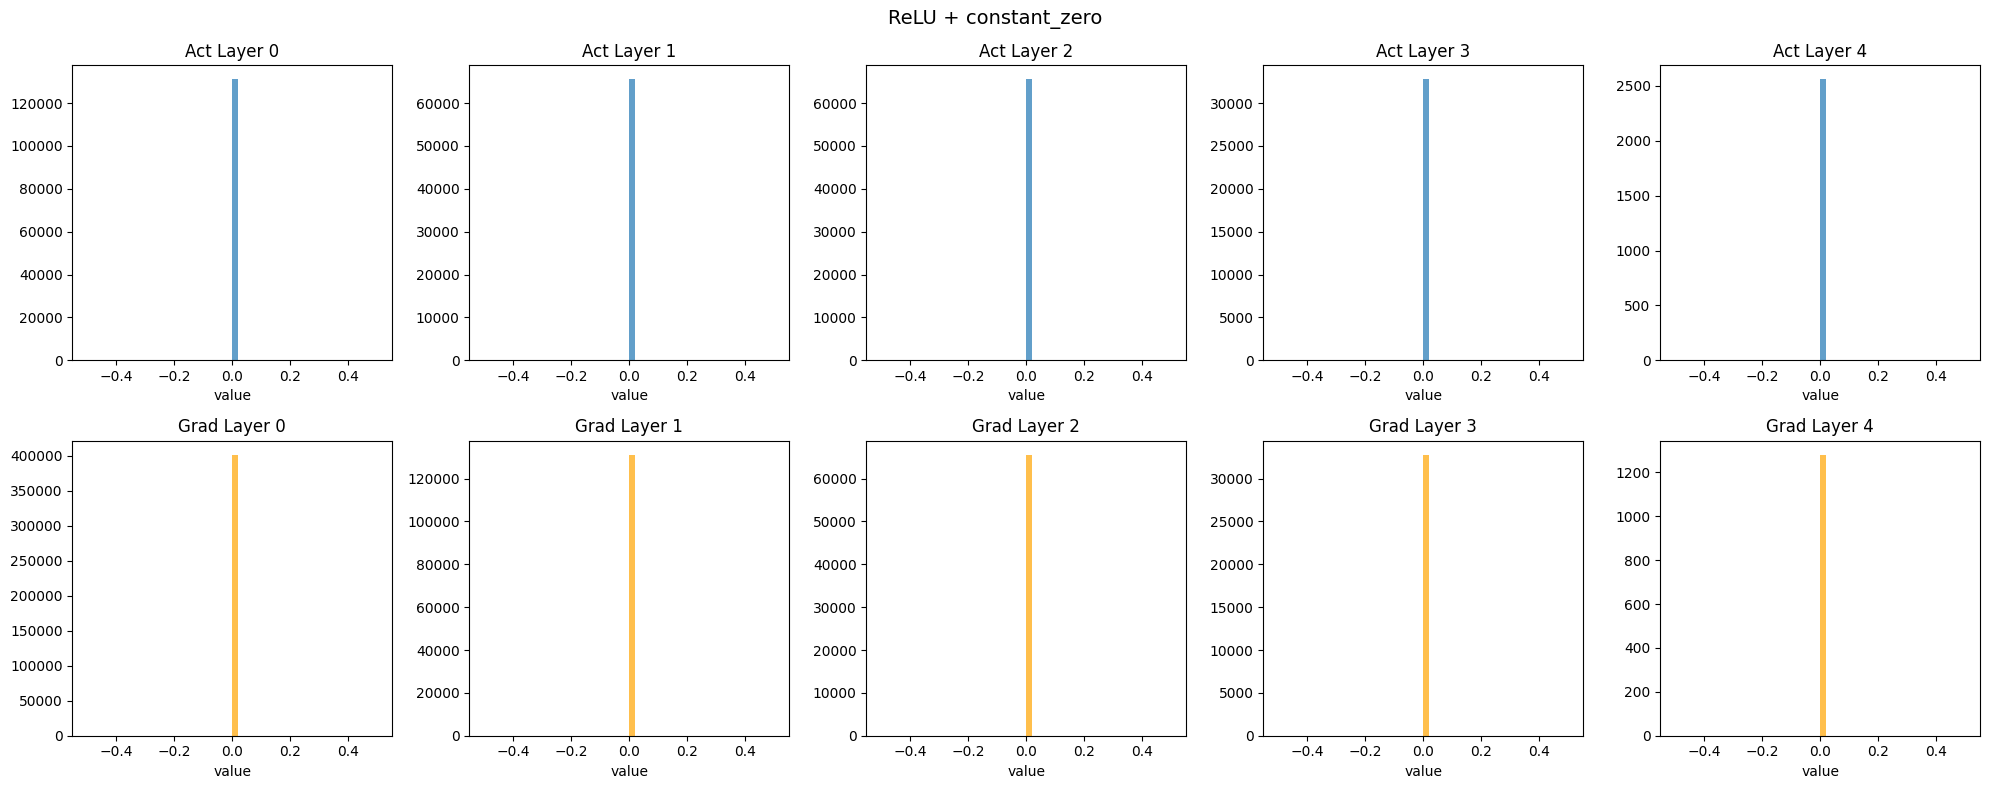

In [7]:
def compare_combinations(combinations):
    x = torch.randn(256, 1, 28, 28)
    y = torch.randint(0, 10, (256,))
    loss_fn = nn.CrossEntropyLoss()

    for act_name, init_name in combinations:
        print(f"\n=== {act_name} + {init_name} ===")
        act_fn = ACTIVATIONS[act_name]
        model = BaseNetwork(act_fn=act_fn)
        use_init(model, init_name)

        acts = get_activations(model, x)
        grads, loss = get_gradients(model, x, y, loss_fn)

        print(f"Loss: {loss:.4f}")
        print(f"Act std по слоям: {[f'{a.std():.4f}' for a in acts]}")
        print(f"Grad std по слоям: {[f'{g.std():.6f}' for g in grads]}")

        plot_histograms(act_name, init_name, acts, grads)

compare_combinations([
    ("ReLU", "kaiming"),        # хорошая
    ("ReLU", "small_normal"),   # плохая — затухание
    ("Tanh", "xavier"),         # хорошая
    ("ReLU", "constant_zero"),  # оч плохая
])

In [8]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import copy

transform = transforms.ToTensor()
train_data = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST("data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=256, shuffle=False)

def train_model(model, train_loader, test_loader, epochs=10, lr=1e-3, verbose_every=5):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)

    history = {
        "train_loss": [],
        "test_loss": [],
        "test_acc": [],
    }

    best_acc = 0.0
    best_state = None

    for epoch in range(epochs):
        # train
        model.train()
        train_loss, n_batches = 0.0, 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
            n_batches += 1

        train_loss /= n_batches

        # test
        model.eval()
        test_loss, correct, total = 0.0, 0, 0

        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)
                preds = model(x)
                test_loss += loss_fn(preds, y).item()
                correct += (preds.argmax(1) == y).sum().item()
                total += y.size(0)

        test_loss /= len(test_loader)
        test_acc = correct / total

        if test_acc > best_acc:
            best_acc = test_acc
            best_state = copy.deepcopy(model.state_dict())

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        if (epoch + 1) % verbose_every == 0 or epoch == 0:
            print(f"Epoch {epoch+1:2d}: "
                  f"train_loss={train_loss:.4f}, "
                  f"test_loss={test_loss:.4f}, "
                  f"test_acc={test_acc:.4f}")

    if best_state is not None:
        model.load_state_dict(best_state)

    return history

In [9]:
COMBINATIONS = [
    ("ReLU", "constant_zero"),
    ("ReLU", "small_normal"),
    ("ReLU", "xavier"),
    ("ReLU", "kaiming"),
    ("Tanh", "small_normal"),
    ("Tanh", "xavier"),
    ("Tanh", "kaiming"),
    ("Identity", "xavier"),
]

histories = {}

for act_name, init_name in COMBINATIONS:
    print(f"\n{'='*60}")
    print(f"{act_name} + {init_name}")
    print('='*60)

    torch.manual_seed(42)
    act_fn = ACTIVATIONS[act_name]
    model = BaseNetwork(act_fn=act_fn).to(device)
    use_init(model, init_name)

    history = train_model(model, train_loader, test_loader, epochs=10)
    histories[(act_name, init_name)] = history


ReLU + constant_zero
Epoch  1: train_loss=2.3026, test_loss=2.3026, test_acc=0.1000
Epoch  5: train_loss=2.3026, test_loss=2.3026, test_acc=0.1000
Epoch 10: train_loss=2.3026, test_loss=2.3026, test_acc=0.1000

ReLU + small_normal
Epoch  1: train_loss=2.3026, test_loss=2.3026, test_acc=0.1509
Epoch  5: train_loss=2.3026, test_loss=2.3026, test_acc=0.1000
Epoch 10: train_loss=2.3026, test_loss=2.3025, test_acc=0.1000

ReLU + xavier
Epoch  1: train_loss=1.1402, test_loss=0.6927, test_acc=0.7588
Epoch  5: train_loss=0.4472, test_loss=0.4526, test_acc=0.8391
Epoch 10: train_loss=0.3816, test_loss=0.4340, test_acc=0.8419

ReLU + kaiming
Epoch  1: train_loss=0.8598, test_loss=0.5773, test_acc=0.8013
Epoch  5: train_loss=0.4085, test_loss=0.4194, test_acc=0.8500
Epoch 10: train_loss=0.3511, test_loss=0.4139, test_acc=0.8474

Tanh + small_normal
Epoch  1: train_loss=2.3026, test_loss=2.3026, test_acc=0.1216
Epoch  5: train_loss=2.3025, test_loss=2.3024, test_acc=0.1000
Epoch 10: train_loss=2.

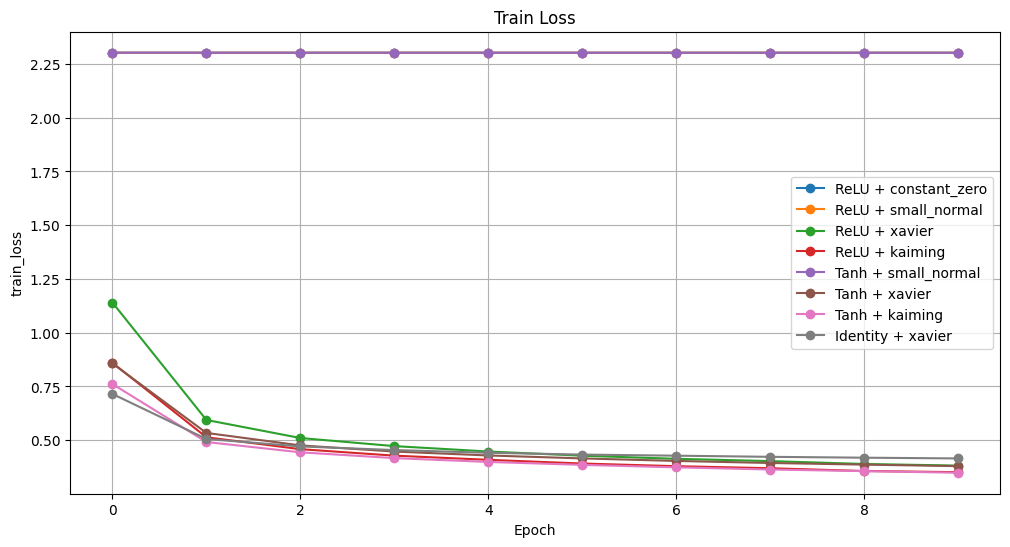

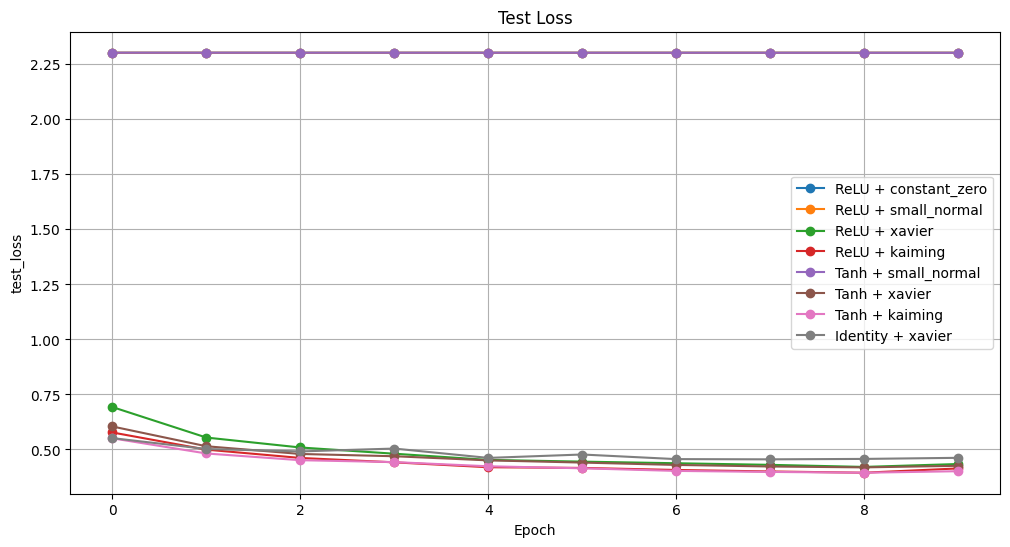

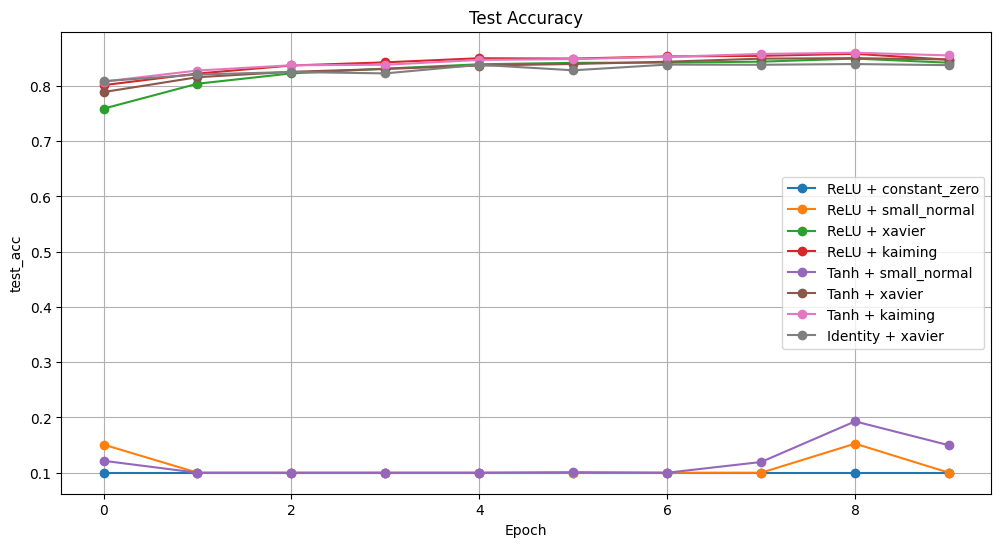

In [10]:
def plot_comparison(histories, metric="test_acc", title="Test Accuracy"):
    plt.figure(figsize=(12, 6))

    for (act_name, init_name), h in histories.items():
        plt.plot(h[metric], label=f"{act_name} + {init_name}", marker='o')

    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

plot_comparison(histories, metric="train_loss", title="Train Loss")
plot_comparison(histories, metric="test_loss", title="Test Loss")
plot_comparison(histories, metric="test_acc", title="Test Accuracy")

In [11]:
import pandas as pd

rows = []
for (act_name, init_name), h in histories.items():
    accs = h["test_acc"]
    best_acc = max(accs)
    best_epoch = accs.index(best_acc) + 1
    last_acc = accs[-1]
    rows.append({
        "Activation": act_name,
        "Init": init_name,
        "Best Acc": round(best_acc, 4),
        "Best Epoch": best_epoch,
        "Last Acc": round(last_acc, 4),
    })

df = pd.DataFrame(rows)
df = df.sort_values("Best Acc", ascending=False).reset_index(drop=True)
print(df)

  Activation           Init  Best Acc  Best Epoch  Last Acc
0       Tanh        kaiming    0.8600           9    0.8551
1       ReLU        kaiming    0.8580           9    0.8474
2       Tanh         xavier    0.8502           9    0.8477
3       ReLU         xavier    0.8494           9    0.8419
4   Identity         xavier    0.8395           9    0.8375
5       Tanh   small_normal    0.1929           9    0.1497
6       ReLU   small_normal    0.1526           9    0.1000
7       ReLU  constant_zero    0.1000           1    0.1000


Дополнительно: ещё одна активация (LeakyReLU)

In [12]:
ACTIVATIONS["LeakyReLU"] = nn.LeakyReLU(0.01)

combos_leaky = [
    ("LeakyReLU", "small_normal"),
    ("LeakyReLU", "xavier"),
    ("LeakyReLU", "kaiming"),
]

for act_name, init_name in combos_leaky:
    print(f"\n=== {act_name} + {init_name} ===")
    torch.manual_seed(42)
    model = BaseNetwork(act_fn=ACTIVATIONS[act_name]).to(device)
    use_init(model, init_name)
    history = train_model(model, train_loader, test_loader, epochs=5)
    histories[(act_name, init_name)] = history


=== LeakyReLU + small_normal ===
Epoch  1: train_loss=2.3026, test_loss=2.3026, test_acc=0.1493
Epoch  5: train_loss=2.3026, test_loss=2.3026, test_acc=0.1000

=== LeakyReLU + xavier ===
Epoch  1: train_loss=1.1391, test_loss=0.6914, test_acc=0.7595
Epoch  5: train_loss=0.4477, test_loss=0.4534, test_acc=0.8390

=== LeakyReLU + kaiming ===
Epoch  1: train_loss=0.8598, test_loss=0.5781, test_acc=0.7999
Epoch  5: train_loss=0.4084, test_loss=0.4198, test_acc=0.8500


# Задание 2

In [13]:
class Node:
	def __init__(self, data, _children=(), _op=''):
		self.data = data
		self.grad = 0
		self._backward = lambda: None
		self._prev = set(_children)
		self._op = _op

	def __repr__(self):
		return f" Element(data={self.data}, grad={self.grad})"

	def __add__(self, other):
		other = other if isinstance(other, Node) else Node(other)
		out = Node(self.data + other.data, (self, other), '+')
		
		def _backward():
			self.grad += out.grad
			other.grad += out.grad
			
		out._backward = _backward
	
		return out
	
	def __mul__(self, other):
		other = other if isinstance(other, Node) else Node(other)
		out = Node(self.data * other.data, (self, other), '*')
		
		def _backward():
			self.grad += other.data * out.grad
			other.grad += self.data * out.grad
			
		out._backward = _backward
		
		return out
	
	def relu(self):
		out = Node(max(0.0, self.data), (self,), 'ReLU')
		
		def _backward():
			self.grad += (out.data > 0) * out.grad
		out._backward = _backward
			
		return out

	def backward(self):
		top = []
		visited = set()
		
		def build_top(v):
			if v not in visited:
				visited.add(v)
				for child in v._prev:
					build_top(child)
				top.append(v)
					
		build_top(self)
		
		self.grad = 1.0
		for v in reversed(top):
			v._backward()

In [14]:
a = Node(2)
b = Node(-3)
c = Node(10)
d = a + b * c
e = d.relu()
e.backward()
print(a, b, c, d, e)

 Element(data=2, grad=0.0)  Element(data=-3, grad=0.0)  Element(data=10, grad=0.0)  Element(data=-28, grad=0.0)  Element(data=0.0, grad=1.0)


In [15]:
d.backward()
print(a, b, c, d, e)

 Element(data=2, grad=1.0)  Element(data=-3, grad=10.0)  Element(data=10, grad=-3.0)  Element(data=-28, grad=1.0)  Element(data=0.0, grad=1.0)


In [ ]:
import unittest

class TestNode(unittest.TestCase):

    def test_add(self):
        a = Node(2)
        b = Node(3)
        c = a + b
        c.backward()
        self.assertEqual(c.data, 5)
        self.assertEqual(a.grad, 1)
        self.assertEqual(b.grad, 1)
        self.assertEqual(c.grad, 1)

    def test_mul(self):
        a = Node(2)
        b = Node(3)
        c = a * b
        c.backward()
        self.assertEqual(c.data, 6)
        self.assertEqual(a.grad, 3)   # dc/da = d(ab)/da = b
        self.assertEqual(b.grad, 2)   # dc/db = d(ab)/db = a

    def test_relu_positive(self):
        a = Node(5)
        b = a.relu()
        b.backward()
        self.assertEqual(b.data, 5)
        self.assertEqual(a.grad, 1) # производная ReLU при x>0 = 1

    def test_relu_negative(self):
        a = Node(-5)
        b = a.relu()
        b.backward()
        self.assertEqual(b.data, 0)
        self.assertEqual(a.grad, 0) # производная ReLU при x<0 = 0

    def test_chain(self):
        a = Node(2)
        b = Node(3)
        c = Node(4)
        d = a + b * c
        d.backward()

        self.assertEqual(d.data, 14)
        self.assertEqual(a.grad, 1)
        self.assertEqual(b.grad, 4)   # c.data
        self.assertEqual(c.grad, 3)   # b.data

    def test_accumulation(self):
        x = Node(3)
        y = x * x
        y.backward()
        self.assertEqual(y.data, 9)
        self.assertEqual(x.grad, 6)  # x * x -> dy/dx = 2x

    def test_accumulation_3(self):
        x = Node(2)
        y = x * x * x
        y.backward()
        self.assertEqual(y.data, 8)
        self.assertEqual(x.grad, 12)  # x * x * x -> 3x^2

    def test_numerical_grad(self):
        # f(x) = relu(x^2 + 3x + 1), при x = 0.5
        def f(x_val):
            x = Node(x_val)
            y = x * x + x * 3 + Node(1) 
            return y.relu().data

        x_val = 0.5
        h = 1e-4
        numerical = (f(x_val + h) - f(x_val - h)) / (2 * h) # = 4

        x = Node(x_val)
        y = x * x + x * 3 + Node(1) # => 2x+3 = 4 - x.grad
        z = y.relu()
        z.backward()

        self.assertAlmostEqual(x.grad, numerical, places=4)

    def test_example_from_hw(self):
        a = Node(2); b = Node(-3); c = Node(10)
        d = a + b * c
        d.backward()
        self.assertEqual(d.data, -28)
        self.assertEqual(a.grad, 1)
        self.assertEqual(b.grad, 10)   # c.data
        self.assertEqual(c.grad, -3)   # b.data


if __name__ == "__main__":
    suite = unittest.TestLoader().loadTestsFromTestCase(TestNode)
    unittest.TextTestRunner(verbosity=2).run(suite)

test_accumulation (__main__.TestNode.test_accumulation) ... ok
test_accumulation_3 (__main__.TestNode.test_accumulation_3) ... ok
test_add (__main__.TestNode.test_add) ... ok
test_chain (__main__.TestNode.test_chain) ... ok
test_example_from_hw (__main__.TestNode.test_example_from_hw) ... ok
test_mul (__main__.TestNode.test_mul) ... ok
test_numerical_grad (__main__.TestNode.test_numerical_grad) ... ok
test_relu_negative (__main__.TestNode.test_relu_negative) ... ok
test_relu_positive (__main__.TestNode.test_relu_positive) ... ok

----------------------------------------------------------------------
Ran 9 tests in 0.015s

OK


# Задание 3

Идея AdamW.

AdamW - это модификация Adam с decoupled weight decay. В классическом Adam weight decay добавляется к градиенту (g = ∇L + λθ), а затем градиент адаптируется через моменты m и v. Это приводит к неправильному поведению: эффективный weight decay зависит от истории градиентов и уменьшается для "шумных" параметров.

AdamW применяет weight decay напрямую к параметрам, не пропуская через моменты:

θ = θ - η·m̂/(√v̂+ε)      # adaptive step

θ = θ - η·λ·θ             # weight decay отдельно

Это даёт более корректную регуляризацию и лучше работает на больших моделях.

Алгоритм:

1. Обновить первый момент: m = β₁·m + (1-β₁)·g
2. Обновить второй момент: v = β₂·v + (1-β₂)·g²
3. Bias correction: m̂ = m/(1-β₁ᵗ), v̂ = v/(1-β₂ᵗ)
4. Adaptive step: θ = θ - η·m̂/(√v̂+ε)
5. Weight decay: θ = θ - η·λ·θ

Параметры по умолчанию: β₁=0.9, β₂=0.999, ε=1e-8, λ=1e-2.

In [5]:
import torch

class AdamW:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        self.params = list(params)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.weight_decay = weight_decay
        self.t = 0

        # состояния для каждого параметра
        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

    def step(self):
        self.t += 1
        with torch.no_grad():
            for i, p in enumerate(self.params):
                if p.grad is None:
                    continue

                g = p.grad

                self.m[i] = self.beta1 * self.m[i] + (1 - self.beta1) * g
                self.v[i] = self.beta2 * self.v[i] + (1 - self.beta2) * (g ** 2)

                # Bias correction
                m_hat = self.m[i] / (1 - self.beta1 ** self.t)
                v_hat = self.v[i] / (1 - self.beta2 ** self.t)

                adaptive_step = m_hat / (v_hat.sqrt() + self.eps)

                p -= self.lr * adaptive_step
                p -= self.lr * self.weight_decay * p

In [20]:
from torch import nn


class TestAdamW(unittest.TestCase):

    def test_matches_pytorch(self):
        torch.manual_seed(0)
        model_1 = nn.Linear(5, 1)
        opt_1 = AdamW(model_1.parameters(), lr=1e-3, weight_decay=1e-2)

        torch.manual_seed(0)
        model_2 = nn.Linear(5, 1)
        opt_2 = torch.optim.AdamW(model_2.parameters(), lr=1e-3, weight_decay=1e-2)

        x = torch.randn(10, 5)
        y = torch.randn(10, 1)
        loss_fn = nn.MSELoss()

        for _ in range(10):
            loss_1 = loss_fn(model_1(x), y)
            opt_1.zero_grad()
            loss_1.backward()
            opt_1.step()

            loss_2 = loss_fn(model_2(x), y)
            opt_2.zero_grad()
            loss_2.backward()
            opt_2.step()

        for p1, p2 in zip(model_1.parameters(), model_2.parameters()):
            self.assertTrue(torch.allclose(p1, p2, atol=1e-5))

    def test_zero_weight_decay_matches_adam(self):  # При weight_decay=0 AdamW == Adam
        torch.manual_seed(1)
        model_1 = nn.Linear(5, 1)
        opt_1 = AdamW(model_1.parameters(), lr=1e-3, weight_decay=0.0)

        torch.manual_seed(1)
        model_2 = nn.Linear(5, 1)
        opt_2 = torch.optim.Adam(model_2.parameters(), lr=1e-3)

        x = torch.randn(10, 5)
        y = torch.randn(10, 1)
        loss_fn = nn.MSELoss()

        for _ in range(5):
            loss_1 = loss_fn(model_1(x), y)
            opt_1.zero_grad()
            loss_1.backward()
            opt_1.step()

            loss_2 = loss_fn(model_2(x), y)
            opt_2.zero_grad()
            loss_2.backward()
            opt_2.step()

        for p1, p2 in zip(model_1.parameters(), model_2.parameters()):
            self.assertTrue(torch.allclose(p1, p2, atol=1e-5))

    def test_zero_grad(self):
        model = nn.Linear(3, 1)
        opt = AdamW(model.parameters(), lr=1e-3)

        x = torch.randn(2, 3)
        y = torch.randn(2, 1)
        loss = nn.MSELoss()(model(x), y)
        loss.backward()

        for p in model.parameters():
            self.assertGreater(p.grad.abs().sum().item(), 0)

        opt.zero_grad()

        for p in model.parameters():
            self.assertEqual(p.grad.abs().sum().item(), 0)

    def test_weights_change(self):  # После step меняются веса
        torch.manual_seed(0)
        model = nn.Linear(3, 1)
        w_before = model.weight.clone()

        opt = AdamW(model.parameters(), lr=1e-2)

        x = torch.randn(2, 3)
        y = torch.randn(2, 1)
        loss = nn.MSELoss()(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()

        self.assertFalse(torch.allclose(model.weight, w_before))

    def test_weight_decay_shrinks_weights(self):
        # При нулевом градиенте (или очень маленьком) weight decay должен уменьшать веса
        torch.manual_seed(0)
        model = nn.Linear(3, 1)
        w1_before = model.weight.clone()
        opt = AdamW(model.parameters(), lr=1e-2, weight_decay=0.1)

        for p in model.parameters():
            p.grad = torch.zeros_like(p)

        opt.step()

        # Веса должны уменьшиться быстрее
        for w_before, w_after in zip(w1_before, model.weight):
            self.assertLess(w_after.norm().item(), w_before.norm().item() + 1e-6)

unittest.TextTestRunner(verbosity=2).run(
    unittest.TestLoader().loadTestsFromTestCase(TestAdamW)
)

test_matches_pytorch (__main__.TestAdamW.test_matches_pytorch) ... ok
test_weight_decay_shrinks_weights (__main__.TestAdamW.test_weight_decay_shrinks_weights) ... ok
test_weights_change (__main__.TestAdamW.test_weights_change) ... ok
test_zero_grad (__main__.TestAdamW.test_zero_grad) ... ok
test_zero_weight_decay_matches_adam (__main__.TestAdamW.test_zero_weight_decay_matches_adam) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.105s

OK


<unittest.runner.TextTestResult run=5 errors=0 failures=0>

Using cpu device
Epoch 1: loss=0.4891, acc=0.8220, grad_norm=1.6124, weight_std=0.0365
Epoch 2: loss=0.3573, acc=0.8676, grad_norm=1.1388, weight_std=0.0438
Epoch 3: loss=0.3221, acc=0.8808, grad_norm=1.0424, weight_std=0.0498
Epoch 4: loss=0.3000, acc=0.8870, grad_norm=0.9807, weight_std=0.0551
Epoch 5: loss=0.2814, acc=0.8952, grad_norm=0.9342, weight_std=0.0599
Epoch 6: loss=0.2641, acc=0.9004, grad_norm=0.9019, weight_std=0.0642
Epoch 7: loss=0.2510, acc=0.9046, grad_norm=0.9078, weight_std=0.0683
Epoch 8: loss=0.2396, acc=0.9096, grad_norm=0.8717, weight_std=0.0721
Epoch 9: loss=0.2278, acc=0.9123, grad_norm=0.8776, weight_std=0.0757
Epoch 10: loss=0.2200, acc=0.9161, grad_norm=0.8812, weight_std=0.0792


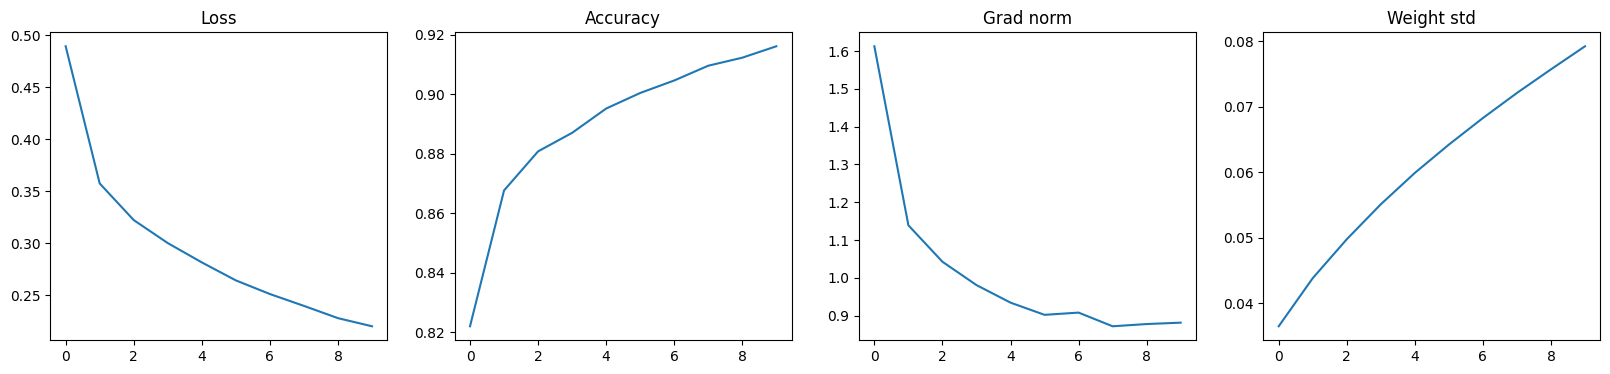

In [6]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

def grad_norm(model):
    total = 0.0
    for p in model.parameters():
        if p.grad is not None:
            total += p.grad.norm().item() ** 2
    return total ** 0.5


def weight_stats(model):
    all_w = torch.cat([p.flatten() for p in model.parameters()])
    return {
        "min": all_w.min().item(),
        "max": all_w.max().item(),
        "mean": all_w.mean().item(),
        "std": all_w.std().item(),
    }

def train_with_optimizer(model, optimizer, dataloader, epochs=10):
    loss_fn = nn.CrossEntropyLoss()
    history = {"loss": [], "grad_norm": [], "weight_std": [], "acc": []}

    for epoch in range(epochs):
        model.train()
        epoch_loss, epoch_grad_norm, n_batches = 0.0, 0.0, 0
        epoch_correct, epoch_total = 0, 0

        for x, y in dataloader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            preds = model(x)
            loss = loss_fn(preds, y)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            epoch_grad_norm += grad_norm(model)
            epoch_correct += (preds.argmax(1) == y).sum().item()
            epoch_total += y.size(0)
            n_batches += 1

        epoch_loss /= n_batches
        epoch_grad_norm /= n_batches
        epoch_acc = epoch_correct / epoch_total
        stats = weight_stats(model)

        history["loss"].append(epoch_loss)
        history["grad_norm"].append(epoch_grad_norm)
        history["weight_std"].append(stats["std"])
        history["acc"].append(epoch_acc)

        print(f"Epoch {epoch+1}: loss={epoch_loss:.4f}, acc={epoch_acc:.4f}, "
              f"grad_norm={epoch_grad_norm:.4f}, weight_std={stats['std']:.4f}")

    return history


class MyFlatten(nn.Module):
    def forward(self, x):
        return x.view(x.size(0), -1)

class NeuralNetwork(nn.Module):
    def __init__(self, use_log_softmax=False):
        super().__init__()
        self.flatten = MyFlatten()
        self.use_log_softmax = use_log_softmax 
        self.fc = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )
        self.log_softmax = nn.LogSoftmax(dim=1)

    def forward(self, x):
        x = self.flatten(x)
        logits = self.fc(x)
        if self.use_log_softmax:
            return self.log_softmax(logits)
        return logits


transform = transforms.ToTensor()
train_data = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)

torch.manual_seed(42)
model = NeuralNetwork().to(device)
opt = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
history = train_with_optimizer(model, opt, train_loader, epochs=10)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].plot(history["loss"]); axes[0].set_title("Loss")
axes[1].plot(history["acc"]); axes[1].set_title("Accuracy")
axes[2].plot(history["grad_norm"]); axes[2].set_title("Grad norm")
axes[3].plot(history["weight_std"]); axes[3].set_title("Weight std")
plt.show()

Epoch 1: loss=0.4893, acc=0.8212, grad_norm=1.6089, weight_std=0.0365
Epoch 2: loss=0.3570, acc=0.8675, grad_norm=1.1312, weight_std=0.0440
Epoch 3: loss=0.3222, acc=0.8811, grad_norm=1.0297, weight_std=0.0500
Epoch 4: loss=0.3004, acc=0.8873, grad_norm=0.9746, weight_std=0.0554
Epoch 5: loss=0.2815, acc=0.8942, grad_norm=0.9451, weight_std=0.0605
Epoch 6: loss=0.2649, acc=0.8999, grad_norm=0.9113, weight_std=0.0649
Epoch 7: loss=0.2502, acc=0.9050, grad_norm=0.9084, weight_std=0.0690
Epoch 8: loss=0.2385, acc=0.9094, grad_norm=0.8751, weight_std=0.0730
Epoch 9: loss=0.2286, acc=0.9136, grad_norm=0.8756, weight_std=0.0767
Epoch 10: loss=0.2201, acc=0.9161, grad_norm=0.8734, weight_std=0.0804


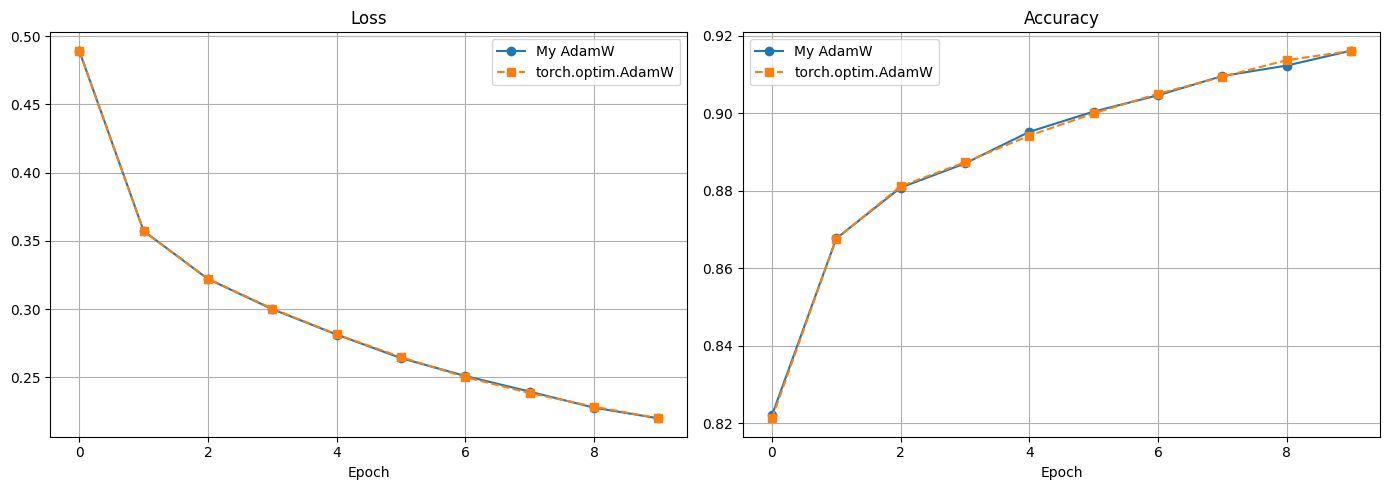

In [7]:
# Обучаем с torch.optim.AdamW
torch.manual_seed(42)
model_torch = NeuralNetwork().to(device)
opt_torch = torch.optim.AdamW(model_torch.parameters(), lr=1e-3, weight_decay=1e-2)
history_torch = train_with_optimizer(model_torch, opt_torch, train_loader, epochs=10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history["loss"], label="My AdamW", marker='o')
axes[0].plot(history_torch["loss"], label="torch.optim.AdamW", marker='s', linestyle='--')
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(history["acc"], label="My AdamW", marker='o')
axes[1].plot(history_torch["acc"], label="torch.optim.AdamW", marker='s', linestyle='--')
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.show()

## Доп. алгоритмы:

Идея Momentum.

Momentum - это модификация SGD с добавлением "инерции" к обновлению весов. В классическом SGD веса обновляются строго в направлении антиградиента (θ = θ - η·g), что приводит к зигзагообразному движению на скачках, где градиент по одному направлению большой, по другому — маленький, и медленной сходимости.

Momentum накапливает "скорость" v — сглаженный градиент, который сохраняет направление движения:

v = β·v + g # накопление скорости

θ = θ - η·v # обновление весов

Это даёт более быстрое движение в нужном направлении и сглаживает зигзаги.

Параметры по умолчанию: β=0.9, η=0.01.

In [ ]:
class Momentum:
    def __init__(self, params, lr=0.01, momentum=0.9):
        self.params = list(params)
        self.lr = lr
        self.momentum = momentum

        # скорость для каждого параметра
        self.velocity = [torch.zeros_like(p) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

    def step(self):
        with torch.no_grad():
            for i, p in enumerate(self.params):
                if p.grad is None:
                    continue

                self.velocity[i] = self.momentum * self.velocity[i] + p.grad

                p -= self.lr * self.velocity[i]

In [ ]:
class TestMomentum(unittest.TestCase):

    def test_matches_pytorch(self):
        # Мой Momentum должен совпасть с torch.optim.SGD(momentum=0.9)
        torch.manual_seed(0)
        model_1 = nn.Linear(5, 1)
        opt_1 = Momentum(model_1.parameters(), lr=0.01, momentum=0.9)

        torch.manual_seed(0)
        model_2 = nn.Linear(5, 1)
        opt_2 = torch.optim.SGD(model_2.parameters(), lr=0.01, momentum=0.9)

        x = torch.randn(10, 5)
        y = torch.randn(10, 1)
        loss_fn = nn.MSELoss()

        for _ in range(10):
            loss_1 = loss_fn(model_1(x), y)
            opt_1.zero_grad()
            loss_1.backward()
            opt_1.step()

            loss_2 = loss_fn(model_2(x), y)
            opt_2.zero_grad()
            loss_2.backward()
            opt_2.step()

        for p1, p2 in zip(model_1.parameters(), model_2.parameters()):
            self.assertTrue(torch.allclose(p1, p2, atol=1e-5))

    def test_zero_momentum_matches_sgd(self):
        # При momentum=0 Momentum == SGD
        torch.manual_seed(1)
        model_1 = nn.Linear(5, 1)
        opt_1 = Momentum(model_1.parameters(), lr=0.1, momentum=0.0)

        torch.manual_seed(1)
        model_2 = nn.Linear(5, 1)
        opt_2 = torch.optim.SGD(model_2.parameters(), lr=0.1)

        x = torch.randn(10, 5)
        y = torch.randn(10, 1)
        loss_fn = nn.MSELoss()

        for _ in range(5):
            loss_1 = loss_fn(model_1(x), y)
            opt_1.zero_grad()
            loss_1.backward()
            opt_1.step()

            loss_2 = loss_fn(model_2(x), y)
            opt_2.zero_grad()
            loss_2.backward()
            opt_2.step()

        for p1, p2 in zip(model_1.parameters(), model_2.parameters()):
            self.assertTrue(torch.allclose(p1, p2, atol=1e-6))

    def test_zero_grad(self):
        # zero_grad обнуляет градиенты
        model = nn.Linear(3, 1)
        opt = Momentum(model.parameters(), lr=0.01, momentum=0.9)

        x = torch.randn(2, 3)
        y = torch.randn(2, 1)
        loss = nn.MSELoss()(model(x), y)
        loss.backward()

        for p in model.parameters():
            self.assertGreater(p.grad.abs().sum().item(), 0)

        opt.zero_grad()

        for p in model.parameters():
            self.assertEqual(p.grad.abs().sum().item(), 0)

    def test_velocity_accumulates(self):
        # После нескольких шагов velocity не ноль
        model = nn.Linear(3, 1)
        opt = Momentum(model.parameters(), lr=0.01, momentum=0.9)

        x = torch.randn(2, 3)
        y = torch.randn(2, 1)
        loss_fn = nn.MSELoss()

        loss = loss_fn(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()

        for v in opt.velocity:
            self.assertGreater(v.abs().sum().item(), 0)

    def test_weights_change(self):
        # После step веса меняются
        torch.manual_seed(0)
        model = nn.Linear(3, 1)
        w_before = model.weight.clone()

        opt = Momentum(model.parameters(), lr=0.1, momentum=0.9)

        x = torch.randn(2, 3)
        y = torch.randn(2, 1)
        loss = nn.MSELoss()(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()

        self.assertFalse(torch.allclose(model.weight, w_before))


unittest.TextTestRunner(verbosity=2).run(
    unittest.TestLoader().loadTestsFromTestCase(TestMomentum)
)

test_matches_pytorch (__main__.TestMomentum.test_matches_pytorch)
Наш Momentum должен совпасть с torch.optim.SGD(momentum=0.9). ... ok
test_velocity_accumulates (__main__.TestMomentum.test_velocity_accumulates)
После нескольких шагов velocity не ноль. ... ok
test_weights_change (__main__.TestMomentum.test_weights_change)
После step веса меняются. ... ok
test_zero_grad (__main__.TestMomentum.test_zero_grad)
zero_grad обнуляет градиенты. ... ok
test_zero_momentum_matches_sgd (__main__.TestMomentum.test_zero_momentum_matches_sgd)
При momentum=0 Momentum == SGD. ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.098s

OK


<unittest.runner.TextTestResult run=5 errors=0 failures=0>

In [9]:
torch.manual_seed(42)
model_momentum = NeuralNetwork().to(device)
opt_momentum = Momentum(model_momentum.parameters(), lr=0.01, momentum=0.9)
history_momentum = train_with_optimizer(model_momentum, opt_momentum, train_loader, epochs=10)

Epoch 1: loss=0.6587, acc=0.7704, grad_norm=1.6615, weight_std=0.0246
Epoch 2: loss=0.4157, acc=0.8504, grad_norm=1.4242, weight_std=0.0255
Epoch 3: loss=0.3710, acc=0.8648, grad_norm=1.3871, weight_std=0.0262
Epoch 4: loss=0.3433, acc=0.8746, grad_norm=1.3646, weight_std=0.0269
Epoch 5: loss=0.3212, acc=0.8813, grad_norm=1.3392, weight_std=0.0276
Epoch 6: loss=0.3038, acc=0.8890, grad_norm=1.3306, weight_std=0.0282
Epoch 7: loss=0.2915, acc=0.8912, grad_norm=1.3552, weight_std=0.0288
Epoch 8: loss=0.2765, acc=0.8969, grad_norm=1.3160, weight_std=0.0293
Epoch 9: loss=0.2676, acc=0.9000, grad_norm=1.3408, weight_std=0.0299
Epoch 10: loss=0.2587, acc=0.9038, grad_norm=1.3450, weight_std=0.0304


Epoch 1: loss=1.3061, acc=0.6090, grad_norm=1.1935, weight_std=0.0233
Epoch 2: loss=0.6828, acc=0.7580, grad_norm=1.7427, weight_std=0.0235
Epoch 3: loss=0.5721, acc=0.8026, grad_norm=1.9067, weight_std=0.0237
Epoch 4: loss=0.5178, acc=0.8206, grad_norm=2.0441, weight_std=0.0239
Epoch 5: loss=0.4866, acc=0.8306, grad_norm=2.0686, weight_std=0.0240
Epoch 6: loss=0.4664, acc=0.8369, grad_norm=2.0877, weight_std=0.0241
Epoch 7: loss=0.4503, acc=0.8415, grad_norm=2.1093, weight_std=0.0242
Epoch 8: loss=0.4381, acc=0.8459, grad_norm=2.0768, weight_std=0.0243
Epoch 9: loss=0.4274, acc=0.8509, grad_norm=2.1038, weight_std=0.0244
Epoch 10: loss=0.4179, acc=0.8545, grad_norm=2.0916, weight_std=0.0245


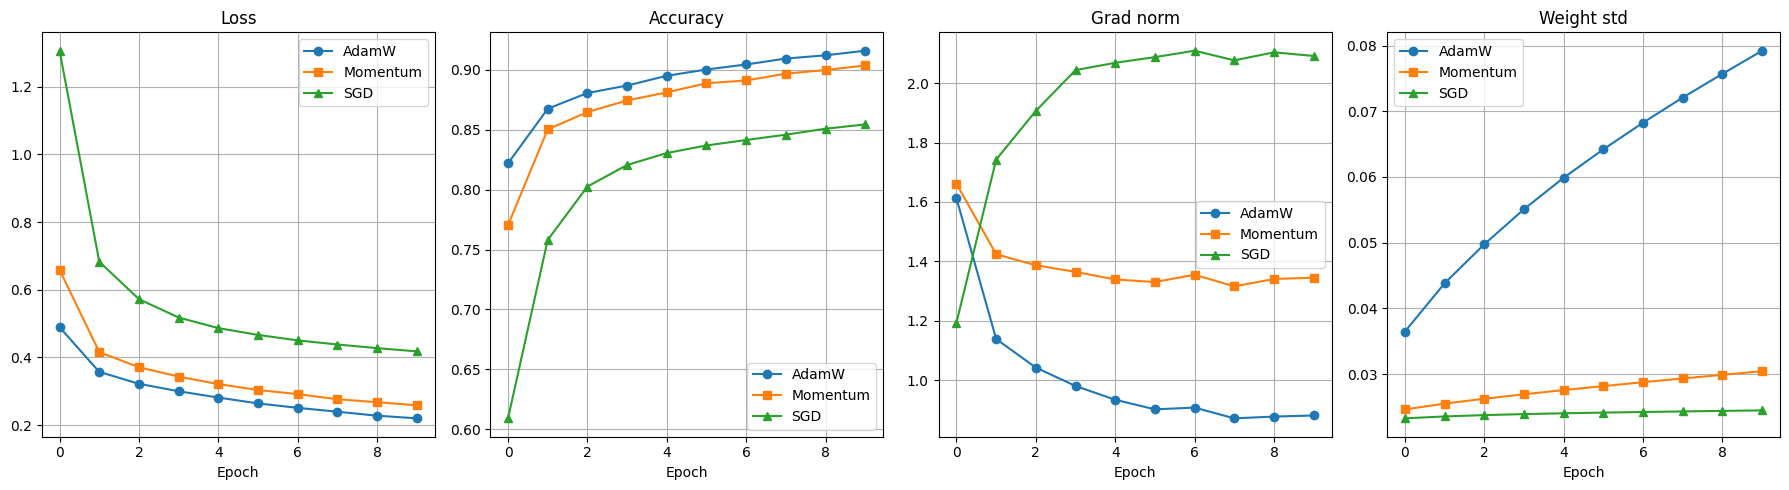

In [10]:
# SGD
torch.manual_seed(42)
model_sgd = NeuralNetwork().to(device)
opt_sgd = torch.optim.SGD(model_sgd.parameters(), lr=0.01)
history_sgd = train_with_optimizer(model_sgd, opt_sgd, train_loader, epochs=10)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].plot(history["loss"], label="AdamW", marker='o')
axes[0].plot(history_momentum["loss"], label="Momentum", marker='s')
axes[0].plot(history_sgd["loss"], label="SGD", marker='^')
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(history["acc"], label="AdamW", marker='o')
axes[1].plot(history_momentum["acc"], label="Momentum", marker='s')
axes[1].plot(history_sgd["acc"], label="SGD", marker='^')
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(True)

axes[2].plot(history["grad_norm"], label="AdamW", marker='o')
axes[2].plot(history_momentum["grad_norm"], label="Momentum", marker='s')
axes[2].plot(history_sgd["grad_norm"], label="SGD", marker='^')
axes[2].set_title("Grad norm"); axes[2].set_xlabel("Epoch"); axes[2].legend(); axes[2].grid(True)

axes[3].plot(history["weight_std"], label="AdamW", marker='o')
axes[3].plot(history_momentum["weight_std"], label="Momentum", marker='s')
axes[3].plot(history_sgd["weight_std"], label="SGD", marker='^')
axes[3].set_title("Weight std"); axes[3].set_xlabel("Epoch"); axes[3].legend(); axes[3].grid(True)

plt.tight_layout()
plt.show()

Идея Adam.

Adam - это оптимизатор, сочетающий три идеи: momentum (накопление первого момента), adaptive learning rate (накопление второго момента) и bias correction. В отличие от SGD, который обновляет все веса с одинаковым шагом η, Adam адаптирует learning rate для каждого параметра отдельно, что ускоряет сходимость и делает обучение устойчивее.

Adam накапливает первый момент m (сглаженный градиент) и второй момент v (сглаженный квадрат градиента), а затем использует их отношение для обновления весов:

m = β₁·m + (1-β₁)·g           # первый момент (momentum)

v = β₂·v + (1-β₂)·g²          # второй момент (adaptive LR)

m̂ = m/(1-β₁ᵗ)                 # bias correction

v̂ = v/(1-β₂ᵗ)                 # bias correction

θ = θ - η·m̂/(√v̂+ε)            # adaptive step

Это даёт быструю сходимость в начале обучения и устойчивость к разным масштабам градиентов.

Алгоритм:

1. Обновить первый момент: m = β₁·m + (1-β₁)·g
2. Обновить второй момент: v = β₂·v + (1-β₂)·g²
3. Bias correction: m̂ = m/(1-β₁ᵗ), v̂ = v/(1-β₂ᵗ)
4. Adaptive step: θ = θ - η·m̂/(√v̂+ε)

Параметры по умолчанию: β₁=0.9, β₂=0.999, ε=1e-8, η=1e-3.

Отличие от AdamW: в Adam нет отдельного weight decay - это чистый adaptive moment. Для маленьких моделей Adam часто обгоняет AdamW, для больших - наоборот.

In [ ]:
class Adam:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        self.params = list(params)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.t = 0

        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

    def step(self):
        self.t += 1
        with torch.no_grad():
            for i, p in enumerate(self.params):
                if p.grad is None:
                    continue

                g = p.grad

                self.m[i] = self.beta1 * self.m[i] + (1 - self.beta1) * g

                self.v[i] = self.beta2 * self.v[i] + (1 - self.beta2) * (g ** 2)

                m_hat = self.m[i] / (1 - self.beta1 ** self.t)
                v_hat = self.v[i] / (1 - self.beta2 ** self.t)

                adaptive_step = m_hat / (v_hat.sqrt() + self.eps)

                # обновление без weight decay
                p -= self.lr * adaptive_step

In [ ]:
class TestAdam(unittest.TestCase):

    def test_matches_pytorch(self):
        # Мой Adam должен совпасть с torch.optim.Adam
        torch.manual_seed(0)
        model_1 = nn.Linear(5, 1)
        opt_1 = Adam(model_1.parameters(), lr=1e-3)

        torch.manual_seed(0)
        model_2 = nn.Linear(5, 1)
        opt_2 = torch.optim.Adam(model_2.parameters(), lr=1e-3)

        x = torch.randn(10, 5)
        y = torch.randn(10, 1)
        loss_fn = nn.MSELoss()

        for _ in range(10):
            loss_1 = loss_fn(model_1(x), y)
            opt_1.zero_grad()
            loss_1.backward()
            opt_1.step()

            loss_2 = loss_fn(model_2(x), y)
            opt_2.zero_grad()
            loss_2.backward()
            opt_2.step()

        for p1, p2 in zip(model_1.parameters(), model_2.parameters()):
            self.assertTrue(torch.allclose(p1, p2, atol=1e-5))

    def test_zero_grad(self):
        # zero_grad обнуляет градиенты
        model = nn.Linear(3, 1)
        opt = Adam(model.parameters(), lr=1e-3)

        x = torch.randn(2, 3)
        y = torch.randn(2, 1)
        loss = nn.MSELoss()(model(x), y)
        loss.backward()

        for p in model.parameters():
            self.assertGreater(p.grad.abs().sum().item(), 0)

        opt.zero_grad()

        for p in model.parameters():
            self.assertEqual(p.grad.abs().sum().item(), 0)

    def test_weights_change(self):
        # После step веса меняются
        torch.manual_seed(0)
        model = nn.Linear(3, 1)
        w_before = model.weight.clone()

        opt = Adam(model.parameters(), lr=1e-2)

        x = torch.randn(2, 3)
        y = torch.randn(2, 1)
        loss = nn.MSELoss()(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()

        self.assertFalse(torch.allclose(model.weight, w_before))

    def test_moments_accumulate(self):
        # После шага m и v не нулевые
        model = nn.Linear(3, 1)
        opt = Adam(model.parameters(), lr=1e-3)

        x = torch.randn(2, 3)
        y = torch.randn(2, 1)
        loss = nn.MSELoss()(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()

        for m in opt.m:
            self.assertGreater(m.abs().sum().item(), 0)
        for v in opt.v:
            self.assertGreater(v.abs().sum().item(), 0)


unittest.TextTestRunner(verbosity=2).run(
    unittest.TestLoader().loadTestsFromTestCase(TestAdam)
)

test_matches_pytorch (__main__.TestAdam.test_matches_pytorch)
Наш Adam должен совпасть с torch.optim.Adam. ... ok
test_moments_accumulate (__main__.TestAdam.test_moments_accumulate)
После шага m и v не нулевые. ... ok
test_weights_change (__main__.TestAdam.test_weights_change)
После step веса меняются. ... ok
test_zero_grad (__main__.TestAdam.test_zero_grad)
zero_grad обнуляет градиенты. ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.024s

OK


<unittest.runner.TextTestResult run=4 errors=0 failures=0>

In [65]:
torch.manual_seed(42)
model_adam = NeuralNetwork().to(device)
opt_adam = Adam(model_adam.parameters(), lr=1e-3)
history_adam = train_with_optimizer(model_adam, opt_adam, train_loader, epochs=10)

Epoch 1: loss=0.4881, acc=0.8215, grad_norm=1.6019, weight_std=0.0365
Epoch 2: loss=0.3566, acc=0.8682, grad_norm=1.1289, weight_std=0.0443
Epoch 3: loss=0.3222, acc=0.8818, grad_norm=1.0247, weight_std=0.0505
Epoch 4: loss=0.2996, acc=0.8883, grad_norm=0.9658, weight_std=0.0561
Epoch 5: loss=0.2795, acc=0.8944, grad_norm=0.9265, weight_std=0.0612
Epoch 6: loss=0.2628, acc=0.9012, grad_norm=0.9043, weight_std=0.0660
Epoch 7: loss=0.2483, acc=0.9063, grad_norm=0.9079, weight_std=0.0706
Epoch 8: loss=0.2355, acc=0.9096, grad_norm=0.8726, weight_std=0.0749
Epoch 9: loss=0.2253, acc=0.9142, grad_norm=0.8717, weight_std=0.0789
Epoch 10: loss=0.2141, acc=0.9172, grad_norm=0.8669, weight_std=0.0828


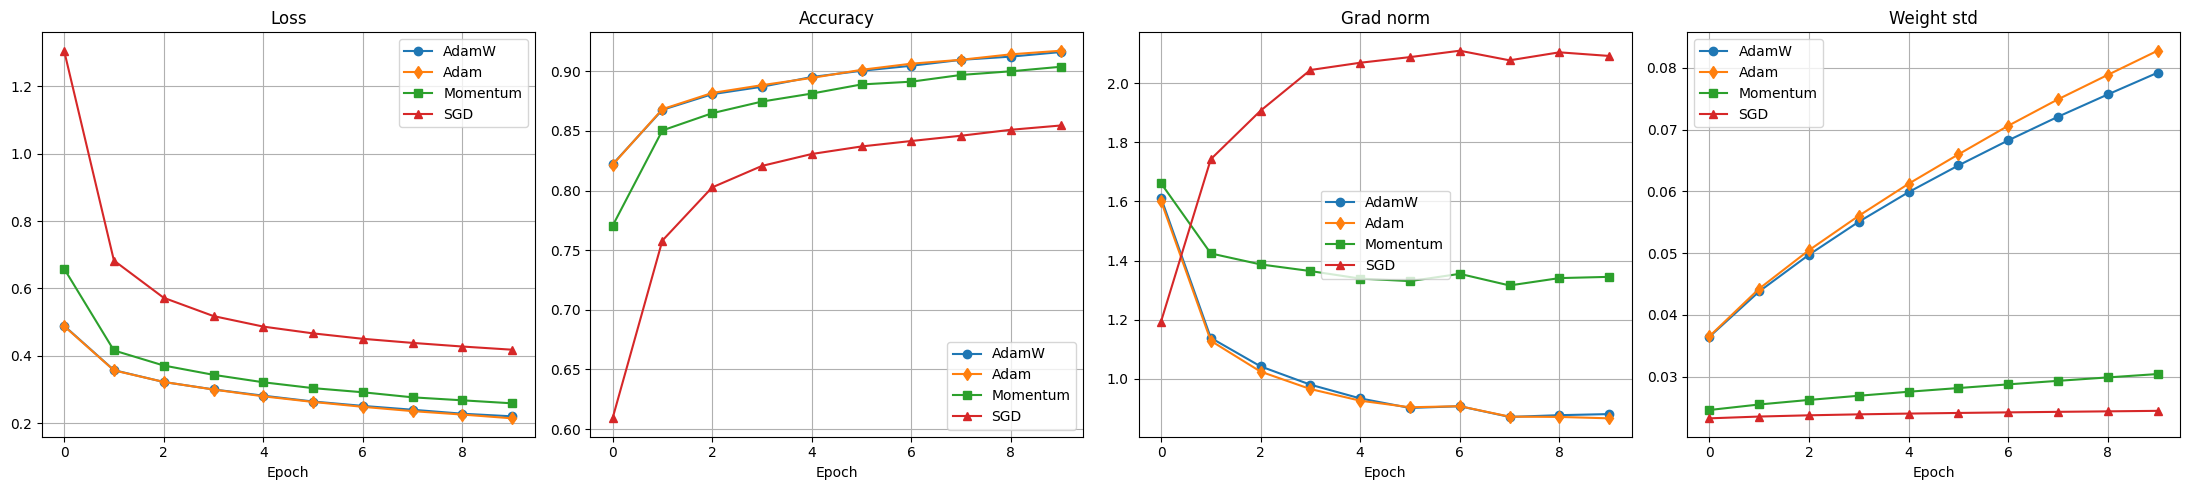

In [66]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# Loss
axes[0].plot(history["loss"], label="AdamW", marker='o')
axes[0].plot(history_adam["loss"], label="Adam", marker='d')
axes[0].plot(history_momentum["loss"], label="Momentum", marker='s')
axes[0].plot(history_sgd["loss"], label="SGD", marker='^')
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(True)

# Accuracy
axes[1].plot(history["acc"], label="AdamW", marker='o')
axes[1].plot(history_adam["acc"], label="Adam", marker='d')
axes[1].plot(history_momentum["acc"], label="Momentum", marker='s')
axes[1].plot(history_sgd["acc"], label="SGD", marker='^')
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(True)

# Grad norm
axes[2].plot(history["grad_norm"], label="AdamW", marker='o')
axes[2].plot(history_adam["grad_norm"], label="Adam", marker='d')
axes[2].plot(history_momentum["grad_norm"], label="Momentum", marker='s')
axes[2].plot(history_sgd["grad_norm"], label="SGD", marker='^')
axes[2].set_title("Grad norm"); axes[2].set_xlabel("Epoch"); axes[2].legend(); axes[2].grid(True)

# Weight std
axes[3].plot(history["weight_std"], label="AdamW", marker='o')
axes[3].plot(history_adam["weight_std"], label="Adam", marker='d')
axes[3].plot(history_momentum["weight_std"], label="Momentum", marker='s')
axes[3].plot(history_sgd["weight_std"], label="SGD", marker='^')
axes[3].set_title("Weight std"); axes[3].set_xlabel("Epoch"); axes[3].legend(); axes[3].grid(True)

plt.tight_layout()
plt.show()

# Задание 4